<a href="https://colab.research.google.com/github/Harsh-L/Quantum-Computing-Introduction/blob/dev/Quantum_Computing_Introduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install qiskit qiskit-aer
!pip install pylatexenc

In [2]:
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector

# Experiment 1

#### 1 qubit, h(0), measure, 1000 shots

#### Identify: counts

In [13]:
qc = QuantumCircuit(1)
qc.h(0)

qc.measure_all()

result = StatevectorSampler().run([qc], shots=1000).result()
print(result[0].data.meas.get_counts())

{'1': 511, '0': 489}


# Experiment 2

#### Same as Experiment 1 but with 10 shots, running 5 times

#### Identify: do the counts change between runs? why?

In [21]:
qc = QuantumCircuit(1)
qc.h(0)

qc.measure_all()

for index in range(5):
  result = StatevectorSampler().run([qc], shots=1000).result()
  print(result[0].data.meas.get_counts())

{'1': 486, '0': 514}
{'1': 498, '0': 502}
{'0': 507, '1': 493}
{'1': 531, '0': 469}
{'0': 470, '1': 530}


# Experiment 3

#### 1 qubit, h(0), no measure

#### Identify: statevector

In [26]:
# Create a circuit without measurement to get its Statevector
qc_state = QuantumCircuit(1)
qc_state.h(0)

# Construct and print the Statevector
state = Statevector(qc_state)
print(state) #[1/√2, 1/√2]

Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))


# Experiment 4

#### 1 qubit, x(0) then h(0), no measure, then with measure

#### Identify: Statevector, then counts

Statevector([ 0.70710678+0.j, -0.70710678+0.j],
            dims=(2,))


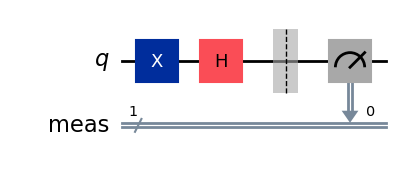


{'0': 51, '1': 49}


In [9]:
qc = QuantumCircuit(1)
qc.x(0)
qc.h(0)

state = Statevector(qc)
print(state)

qc.measure_all()

# # Returning the figure directly allows Colab to render the image
display(qc.draw('mpl'))

print('')
result = StatevectorSampler().run([qc], shots=100).result()
print(result[0].data.meas.get_counts())

# Experiment 5

#### 1 qubit, h(0) twice, measure

#### Identify: Counts

In [28]:
qc = QuantumCircuit(1)
qc.h(0)
qc.h(0)

qc.measure_all()

result = StatevectorSampler().run([qc], shots=1000).result()
print(result[0].data.meas.get_counts())

{'0': 1000}


# Experiment 6

#### 2 qubits, h(0) and h(1), no measure

#### Identify: Statevector

In [29]:
qc = QuantumCircuit(2)
qc.h(0)
qc.h(1)

state = Statevector(qc)
print(state)

Statevector([0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j],
            dims=(2, 2))


# Experiment 7

#### 2 qubits, h(0), measure

#### Identify: which outcomes appear? which never do?

In [39]:
qc = QuantumCircuit(2)
qc.h(0)

qc.measure_all()

result = StatevectorSampler().run([qc], shots=1000).result()
print(result[0].data.meas.get_counts())

{'00': 510, '01': 490}


# Experiment 8

In [40]:
from qiskit.quantum_info import Statevector

# 1. Normalization check
for v in [[0.5, 0.5], [0.6, 0.8], [1, 1]]:
    sv = Statevector(v)
    print(v, "valid:", sv.is_valid())

print(Statevector([0.6, 0.8]).probabilities())   # predict before running

# 2. Same probabilities, different states
from qiskit import QuantumCircuit
plus = QuantumCircuit(1);  plus.h(0)
minus = QuantumCircuit(1); minus.x(0); minus.h(0)
print(Statevector(plus).probabilities(), Statevector(minus).probabilities())
plus.h(0); minus.h(0)                             # now add one more H to each
print(Statevector(plus), Statevector(minus))      # predict before running

[0.5, 0.5] valid: False
[0.6, 0.8] valid: True
[1, 1] valid: False
[0.36 0.64]
[0.5 0.5] [0.5 0.5]
Statevector([1.+0.j, 0.+0.j],
            dims=(2,)) Statevector([0.+0.j, 1.+0.j],
            dims=(2,))


# Phase, Z Gate and interference